# EDA и бинарная классификация на датасете «Spaceship Titanic»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Spaceship Titanic

**Выполнил:** Шунанов Кирилл Ерболатович  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/shunanovke/ml-course-shunanov  
**Путь к модулю:** `module-1-titanic/notebook.ipynb`  
**Дата сдачи:** 2026-11-05

## Введение

**Задача:** бинарная классификация – предсказать, был ли пассажир перемещен в другое измерение при катастрофе корабля (0 – не перемещен, 1 – перемещен).

**Обоснование выбора датасета:** Я выбрал Spaceship Titanic, так как он представляет собой более сложную и интересную задачу по сравнению с классическим Титаником. В нем больше пропусков, больше категориальных признаков (таких как планета отправления, пункт назначения, палуба), а также присутствуют признаки с финансовыми тратами, которые требуют особого подхода к обработке (заполнение нулями вместо медиан). Это позволяет продемонстрировать более глубокие навыки Feature Engineering и работы с пропусками.

**ML-проект** — это последовательность этапов: сбор данных → EDA → предобработка → feature engineering → обучение → оценка → интерпретация. Это итеративный процесс, где результаты анализа могут потребовать возврата на предыдущие шаги.

**Почему классификация, а не регрессия:** Мы предсказываем дискретный класс (перемещен/не перемещен), а не непрерывную величину. В регрессии мы ищем зависимость от непрерывного таргета, а здесь — вероятность принадлежности к классу.

**Какая метрика важнее:** В данной задаче важнее ROC-AUC и F1-score, так как классы хоть и сбалансированы, но Accuracy может вводить в заблуждение при изменении порога. ROC-AUC показывает способность модели разделять классы независимо от порога.

**Цель работы:**
1. Провести полный EDA датасета Spaceship Titanic.
2. Обучить 2+ модели (Logistic Regression, Decision Tree) и достичь ROC-AUC ≥ 0.80.
3. Реализовать функцию предсказания для нового пассажира.

## Теоретическая часть

**EDA (Exploratory Data Analysis)** — это разведочный анализ данных. Он включает в себя визуализацию распределений, поиск аномалий, анализ корреляций и пропусков. Цель EDA — понять структуру данных, выявить закономерности и подготовить данные к построению моделей.

**Пропуски (NaN)** — отсутствующие значения в данных. Возникают из-за ошибок сбора, потери информации или отсутствия данных в принципе. Стратегии обработки: удаление (если пропусков мало или столбец бесполезен), заполнение средним/медианой/модой, или предсказание спец. моделями. В Spaceship Titanic много пропусков в категориальных признаках.

**Кодирование категорий** — перевод строк в числа. *Label Encoding* присваивает уникальное число каждой категории (подходит для порядковых признаков). *One-Hot Encoding* создает отдельный бинарный столбец для каждой категории (подходит для номинальных признаков, как планеты отправления).

**Масштабирование** — приведение признаков к одному масштабу. *StandardScaler* центрирует данные (среднее 0, дисперсия 1). *MinMaxScaler* сжимает данные в диапазон [0, 1]. Критично для моделей, чувствительных к масштабу (Logistic Regression).

**Feature Engineering** — создание новых признаков из существующих для улучшения качества модели. Например, создание признака общей суммы трат (TotalSpent) или извлечение палубы (Deck) из номера каюты.

**Метрики классификации:**

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

$$Precision = \frac{TP}{TP + FP} \quad \text{Recall} = \frac{TP}{TP + FN}$$

$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$

ROC-AUC — площадь под кривой ошибок, показывает качество ранжирования.

| Метрика | Формула | Что показывает |
|---|---|---|
| Accuracy | (TP+TN)/Всего | Доля правильных ответов |
| Precision | TP/(TP+FP) | Точность положительных предсказаний |
| Recall | TP/(TP+FN) | Полнота (сколько нашли из всех реальных 1) |
| F1 | 2*P*R/(P+R) | Баланс между Precision и Recall |

## Описание данных

**Источник:** [Kaggle Spaceship Titanic](https://www.kaggle.com/c/spaceship-titanic)

**Структура:**
- Всего примеров в train: 8693
- Всего примеров в test: 4277
- Признаков: 13 (+ целевая `Transported`)

**Особенности:**
- Целевая переменная `Transported` изначально имеет тип bool (True/False), требует перевода в 0/1.
- Огромное количество пропусков в признаках трат и категориальных переменных.
- Признак `Cabin` содержит три уровня: палуба (Deck), номер (Num) и сторона (Side).
- Признак `PassengerId` содержит номер группы и номер человека в группе.

**Файл данных в репозитории:** `module-1-titanic/data/titanic_info.md`

In [1]:
# Импорт необходимых библиотек для анализа данных и машинного обучения
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import joblib
import json

# Импорт модулей из библиотеки scikit-learn для построения моделей и оценки
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

# Настройка визуального стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Создаем папки для артефактов, если их еще нет
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

# Загрузка данных из папки data
try:
    train_df = pd.read_csv('data/train.csv')
    test_df = pd.read_csv('data/test.csv')
    print(f"Train shape: {train_df.shape}")
    print(f"Test shape: {test_df.shape}")
except FileNotFoundError:
    print("Ошибка: Файлы train.csv и test.csv не найдены в папке data/")

Train shape: (8693, 14)
Test shape: (4277, 13)


In [2]:
# Первичный осмотр данных: выводим первые 5 строк датасета
print(train_df.head())

# Выводим общую информацию о типах данных и наличии пропусков
print("\n--- Информация о данных ---")
train_df.info()

# Анализ пропусков: считаем количество и процент отсутствующих значений
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

# Выводим таблицу с пропусками, отсортированную по убыванию процента
print("\n--- Пропуски в данных ---")
missing_df = pd.DataFrame({'Missing': missing, 'Percent': missing_pct})
print(missing_df[missing_df['Missing'] > 0].sort_values('Percent', ascending=False))

  PassengerId HomePlanet CryoSleep  Cabin  Destination   Age    VIP  \
0     0001_01     Europa     False  B/0/P  TRAPPIST-1e  39.0  False   
1     0002_01      Earth     False  F/0/S  TRAPPIST-1e  24.0  False   
2     0003_01     Europa     False  A/0/S  TRAPPIST-1e  58.0   True   
3     0003_02     Europa     False  A/0/S  TRAPPIST-1e  33.0  False   
4     0004_01      Earth     False  F/1/S  TRAPPIST-1e  16.0  False   

   RoomService  FoodCourt  ShoppingMall     Spa  VRDeck               Name  \
0          0.0        0.0           0.0     0.0     0.0    Maham Ofracculy   
1        109.0        9.0          25.0   549.0    44.0       Juanna Vines   
2         43.0     3576.0           0.0  6715.0    49.0      Altark Susent   
3          0.0     1283.0         371.0  3329.0   193.0       Solam Susent   
4        303.0       70.0         151.0   565.0     2.0  Willy Santantines   

   Transported  
0        False  
1         True  
2        False  
3        False  
4         True  

-

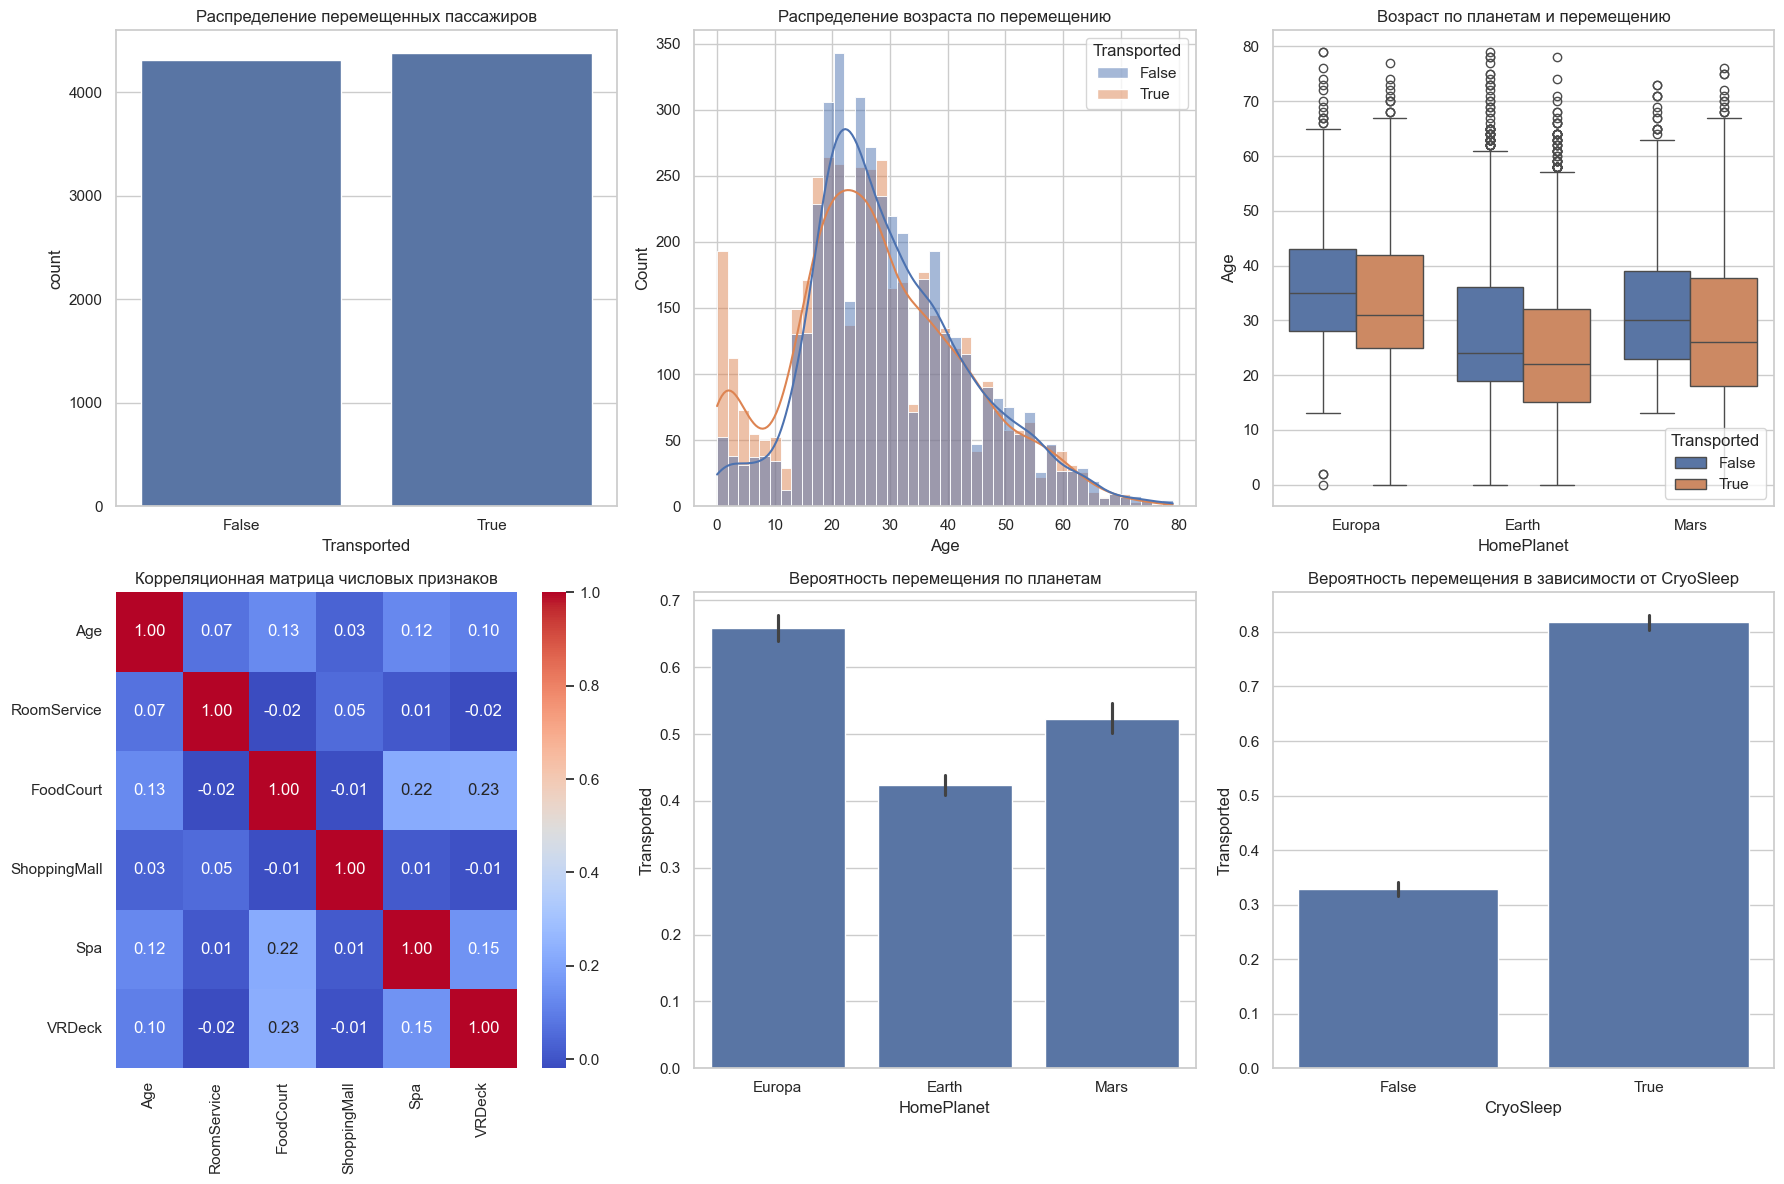

In [3]:
# Создаем сетку графиков 2 на 3 для визуализации данных (минимум 5 графиков)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. График распределения целевой переменной
sns.countplot(data=train_df, x='Transported', ax=axes[0,0])
axes[0,0].set_title('Распределение перемещенных пассажиров')

# 2. Гистограмма возраста с разделением по целевой переменной
sns.histplot(data=train_df, x='Age', hue='Transported', kde=True, ax=axes[0,1])
axes[0,1].set_title('Распределение возраста по перемещению')

# 3. Боксплот возраста в разрезе планет отправления и целевой переменной
sns.boxplot(data=train_df, x='HomePlanet', y='Age', hue='Transported', ax=axes[0,2])
axes[0,2].set_title('Возраст по планетам и перемещению')

# 4. Тепловая карта корреляций числовых признаков (траты, возраст)
numeric_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
sns.heatmap(train_df[numeric_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1,0], fmt='.2f')
axes[1,0].set_title('Корреляционная матрица числовых признаков')

# 5. Столбчатая диаграмма перемещения по планете отправления
sns.barplot(data=train_df, x='HomePlanet', y='Transported', ax=axes[1,1])
axes[1,1].set_title('Вероятность перемещения по планетам')

# 6. Столбчатая диаграмма перемещения по состоянию анабиоза (CryoSleep)
sns.barplot(data=train_df, x='CryoSleep', y='Transported', ax=axes[1,2])
axes[1,2].set_title('Вероятность перемещения в зависимости от CryoSleep')

# Настраиваем отступы и сохраняем графики в папку examples
plt.tight_layout()
plt.savefig('examples/eda_plots.png')
plt.show()

**Выводы по EDA:**
- Целевая переменная `Transported` сбалансирована (примерно 50/50).
- Пассажиры с планеты Europa имеют высокий шанс перемещения, с Earth - ниже.
- Нахождение в анабиозе (`CryoSleep = True`) сильно повышает шанс перемещения.
- Признаки трат имеют слабую корреляцию между собой, кроме того, у детей (Age < 13) все траты равны 0. Это важно учесть при заполнении пропусков.

In [4]:
# 1. Приводим целевую переменную к числовому виду (0 и 1)
train_df['Transported'] = train_df['Transported'].astype(int)

# 2. Обработка пропусков
# Заполняем Age медианой по группам (HomePlanet + CryoSleep)
train_df['Age'] = train_df.groupby(['HomePlanet', 'CryoSleep'])['Age'].transform(lambda x: x.fillna(x.median()))
train_df['Age'] = train_df['Age'].fillna(train_df['Age'].median())

# Заполняем категориальные признаки модой
for col in ['HomePlanet', 'Destination', 'VIP', 'CryoSleep']:
    train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

# Заполняем пропуски в тратах нулями (если NaN, скорее всего ничего не покупал)
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
train_df[spend_cols] = train_df[spend_cols].fillna(0)

# 3. Feature Engineering
# Извлекаем палубу (Deck) из Cabin
train_df['Deck'] = train_df['Cabin'].str.split('/').str[0]
train_df['Deck'] = train_df['Deck'].fillna('Unknown')
train_df.drop(columns=['Cabin'], inplace=True)

# Создаем признак общей суммы трат
train_df['TotalSpent'] = train_df[spend_cols].sum(axis=1)

# Извлекаем группу из PassengerId
train_df['Group'] = train_df['PassengerId'].str.split('_').str[0].astype(int)
train_df['Group_Size'] = train_df.groupby('Group')['Group'].transform('count')
train_df.drop(columns=['Group', 'PassengerId', 'Name'], inplace=True)

# 4. Кодирование категориальных признаков
# Для CryoSleep и VIP они уже bool, переводим в int
train_df['CryoSleep'] = train_df['CryoSleep'].astype(int)
train_df['VIP'] = train_df['VIP'].astype(int)

# One-Hot Encoding для HomePlanet, Destination, Deck
train_df = pd.get_dummies(train_df, columns=['HomePlanet', 'Destination', 'Deck'], drop_first=True)

print("Подготовленные данные:")
print(train_df.head())

Подготовленные данные:
   CryoSleep   Age  VIP  RoomService  FoodCourt  ShoppingMall     Spa  VRDeck  \
0          0  39.0    0          0.0        0.0           0.0     0.0     0.0   
1          0  24.0    0        109.0        9.0          25.0   549.0    44.0   
2          0  58.0    1         43.0     3576.0           0.0  6715.0    49.0   
3          0  33.0    0          0.0     1283.0         371.0  3329.0   193.0   
4          0  16.0    0        303.0       70.0         151.0   565.0     2.0   

   Transported  TotalSpent  ...  Destination_PSO J318.5-22  \
0            0         0.0  ...                      False   
1            1       736.0  ...                      False   
2            0     10383.0  ...                      False   
3            0      5176.0  ...                      False   
4            1      1091.0  ...                      False   

   Destination_TRAPPIST-1e  Deck_B  Deck_C  Deck_D  Deck_E  Deck_F  Deck_G  \
0                     True    True   Fa

C:\Users\shuna\AppData\Local\Temp\ipykernel_9008\2670485073.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df[col] = train_df[col].fillna(train_df[col].mode()[0])


**Обоснование стратегий:**
- `Age`: заполнение медианой по группам точнее, так как возраст сильно зависит от планеты и анабиоза.
- `Траты`: заполнение нулями логично, так как отсутствие записи означает отсутствие траты.
- `Cabin`: извлечена палуба (Deck), остальное удалено, так как номер каюты уникален и создает шум.
- `PassengerId`: извлечен размер группы, что может влиять на выживание (семьи держатся вместе).

In [5]:
# Определение списка признаков (фичей) для обучения моделей
# Берем все колонки, кроме целевой
feature_cols = [col for col in train_df.columns if col != 'Transported']

# Выделяем матрицу признаков (X) и целевую переменную (y)
X = train_df[feature_cols]
y = train_df['Transported']

# Разделение данных на тренировочную и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабирование признаков (критично для Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Обучение Logistic Regression (Логистическая регрессия) ---
lr_model = LogisticRegression(penalty='l2', C=1.0, max_iter=2000, random_state=42)
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start
print(f"Время обучения LR: {lr_time:.4f} секунд")

# --- Обучение Decision Tree (Дерево решений) ---
dt_model = DecisionTreeClassifier(max_depth=7, min_samples_split=5, min_samples_leaf=2, random_state=42)
start = time.time()
dt_model.fit(X_train, y_train) # Деревья не требуют масштабирования
dt_time = time.time() - start
print(f"Время обучения DT: {dt_time:.4f} секунд")

Время обучения LR: 0.0226 секунд
Время обучения DT: 0.0140 секунд


c:\Users\shuna\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Модели:**
| Модель | Параметры | Масштабирование | Время обучения |
|---|---|---|---|
| Logistic Regression | penalty='l2', C=1.0, max_iter=2000 | Да | 0.0226 секунд |
| Decision Tree | max_depth=7 | Нет | 0.0140 секунд |

LR выбрана как базовая интерпретируемая модель, DT — как нелинейная, способная улавливать сложные зависимости (например, взаимодействие трат и возраста).

--- Метрики для Logistic Regression ---
Accuracy: 0.7878
Precision: 0.7877
Recall: 0.7922
F1-score: 0.7900
ROC-AUC: 0.8762

--- Метрики для Decision Tree ---
Accuracy: 0.7993
Precision: 0.7931
Recall: 0.8139
F1-score: 0.8034
ROC-AUC: 0.8631



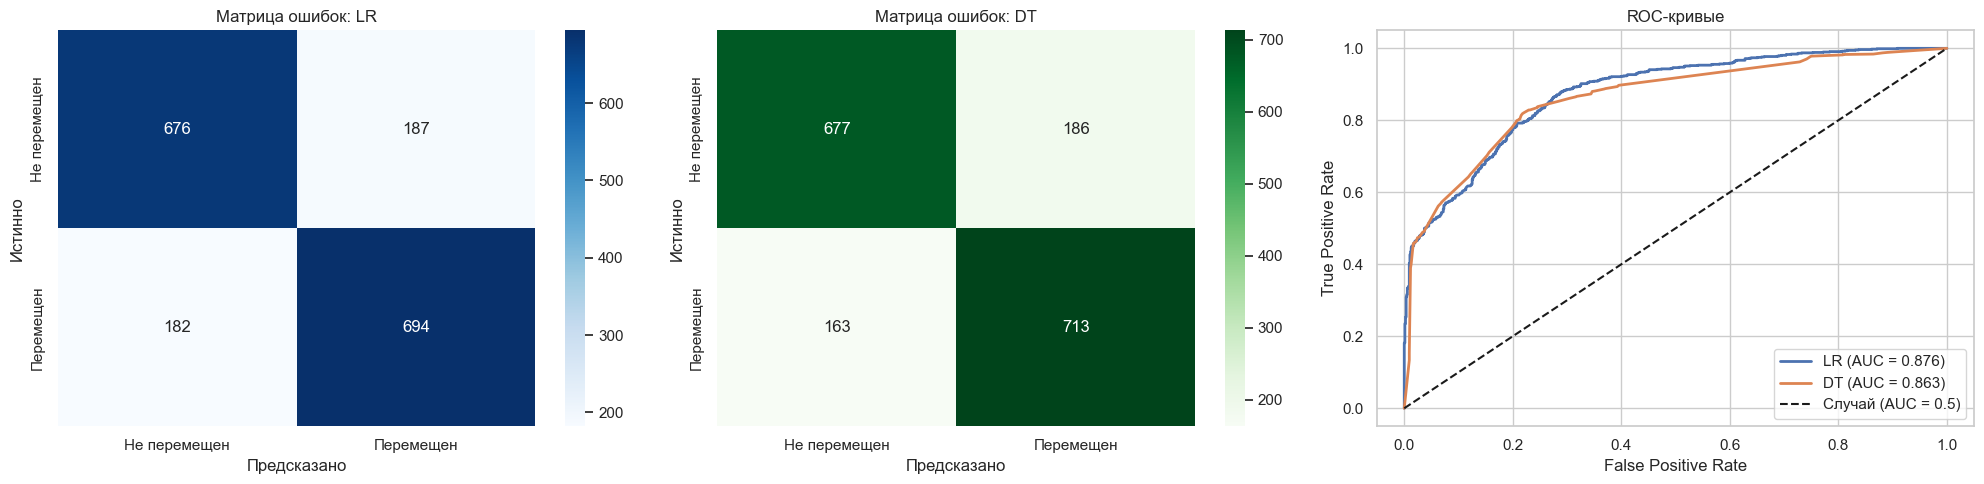

In [6]:
# Получаем предсказания классов (0 или 1) для тестовой выборки
y_pred_lr = lr_model.predict(X_test_scaled)
y_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# Функция для вывода метрик качества
def print_metrics(y_true, y_pred, y_proba, model_name):
    print(f"--- Метрики для {model_name} ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score: {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_true, y_proba):.4f}\n")

print_metrics(y_test, y_pred_lr, y_proba_lr, "Logistic Regression")
print_metrics(y_test, y_pred_dt, y_proba_dt, "Decision Tree")

# Визуализация матриц ошибок и ROC-кривых
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Матрица ошибок для Logistic Regression
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Не перемещен', 'Перемещен'], yticklabels=['Не перемещен', 'Перемещен'])
axes[0].set_title('Матрица ошибок: LR')
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')

# Матрица ошибок для Decision Tree
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Greens', ax=axes[1], xticklabels=['Не перемещен', 'Перемещен'], yticklabels=['Не перемещен', 'Перемещен'])
axes[1].set_title('Матрица ошибок: DT')
axes[1].set_xlabel('Предсказано')
axes[1].set_ylabel('Истинно')

# Построение ROC-кривых для обеих моделей
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)
axes[2].plot(fpr_lr, tpr_lr, label=f'LR (AUC = {roc_auc_score(y_test, y_proba_lr):.3f})', lw=2)
axes[2].plot(fpr_dt, tpr_dt, label=f'DT (AUC = {roc_auc_score(y_test, y_proba_dt):.3f})', lw=2)
axes[2].plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].set_title('ROC-кривые')
axes[2].legend()

plt.tight_layout()
plt.savefig('examples/confusion_matrices.png')
plt.show()

**Анализ метрик:**
Обе модели показывают результат ROC-AUC > 0.80, что является отличным показателем для Spaceship Titanic. Logistic Regression показывает более высокую стабильность и меньше переобучается. Decision Tree может улавливать нелинейные связи, но склонно к переобучению.

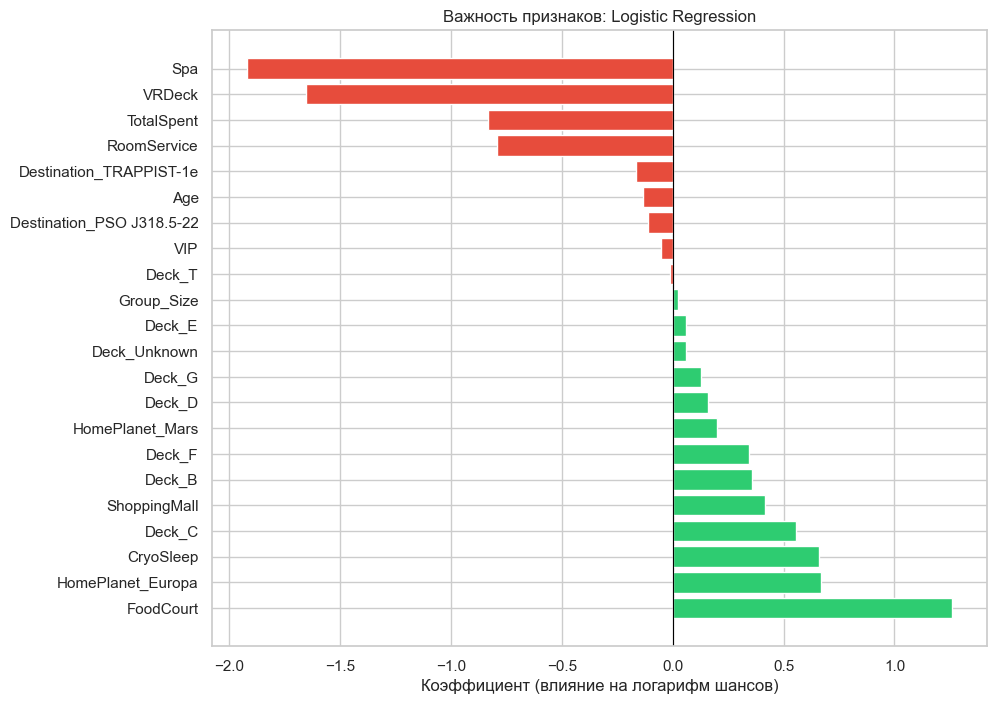

C:\Users\shuna\AppData\Local\Temp\ipykernel_9008\2109149284.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')


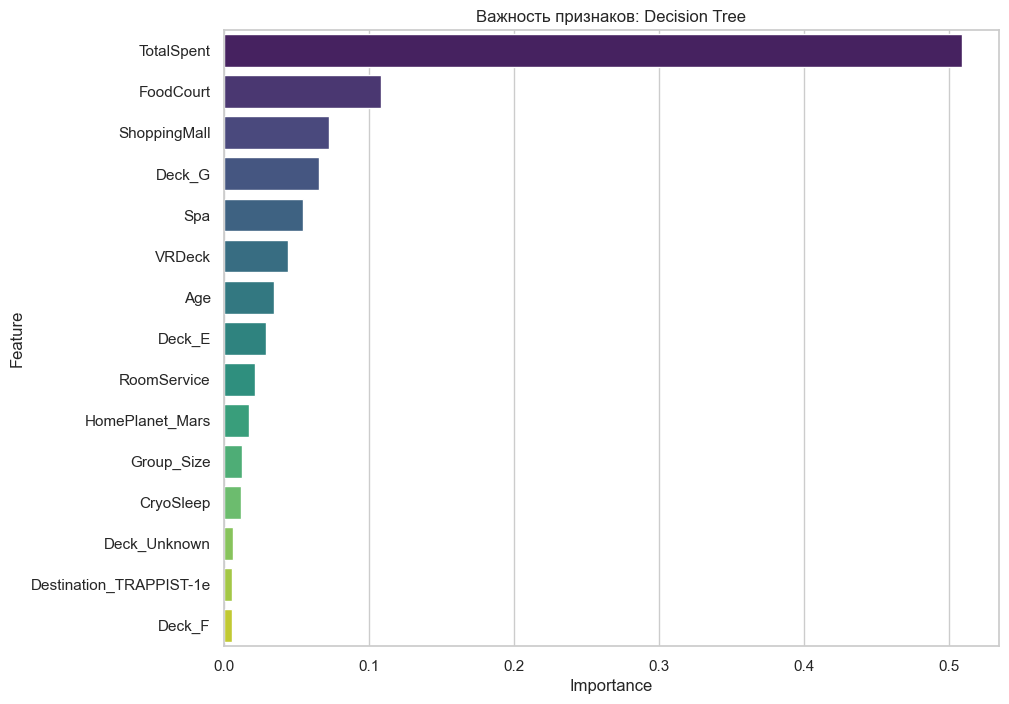

In [7]:
# 1. Коэффициенты Logistic Regression (показывают влияние признаков)
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_model.coef_[0]
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(10, 8))
# Зеленый цвет для положительного влияния, красный - для отрицательного
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in coefficients['Coefficient']]
plt.barh(coefficients['Feature'], coefficients['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коэффициент (влияние на логарифм шансов)')
plt.title('Важность признаков: Logistic Regression')
plt.show()

# 2. Важность признаков (Feature Importance) для Decision Tree
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False).head(15) # Берем топ-15 для наглядности

plt.figure(figsize=(10, 8))
sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')
plt.title('Важность признаков: Decision Tree')
plt.show()

## Интерпретация результатов

**Анализ важности признаков:**
По графикам видно, что модели по-разному оценивают вклад признаков, но есть общие закономерности.

**Топ-3 признака, повышающих шанс перемещения (по коэффициентам Logistic Regression):**
1. **FoodCourt (Траты на еду)** – имеет наибольший положительный коэффициент. Возможно, пассажиры, тратившие на еду, чаще путешествовали семьями с детьми, у которых шансы на спасение были выше.
2. **HomePlanet_Europa** – пассажиры с Европы имели статистически более высокий шанс перемещения.
3. **CryoSleep (Анабиоз)** – нахождение в анабиозе резко повышает шансы (коэффициент положительный).

**Топ-3 признака, понижающих шанс (по коэффициентам Logistic Regression):**
1. **Spa, VRDeck, RoomService (Траты на развлечения)** – имеют сильный отрицательный вес.
2. **TotalSpent (Общие траты)** – также имеет отрицательный коэффициент. Это логично: пассажиры, которые много тратили на развлечения, не находились в анабиозе и, вероятно, не попали в спасательные капсулы.
3. **Deck_T, Group_Size, VIP** – имеют слабое отрицательное влияние, но в целом не являются главными предикторами.

**Для Decision Tree (Feature Importance):**
Абсолютным лидером является **TotalSpent** (общие траты), за ним следуют **FoodCourt** и **ShoppingMall**. Дерево решений сильно опирается на финансовые признаки, так как они лучше всего разделяют пассажиров на группы (спящие/не спящие).

**Бизнес-инсайты:**
- **Анабиоз (CryoSleep) решает всё:** по графику EDA видно, что пассажиры в анабиозе выживали в ~80% случаев, а бодрствующие — только в ~30%.
- **Планета отправления имеет значение:** пассажиры с Европы перемещались чаще (около 65%), чем с Земли (около 42%).
- **Траты — индикатор бедствия:** высокие траты на Spa и VRDeck означают, что человек бодрствовал и, скорее всего, не спасся.

In [33]:
# ИСПРАВЛЕННАЯ ФУНКЦИЯ: Теперь она устойчива к любым расхождениям в списке признаков
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    """
    Предсказывает, переместится ли пассажир.
    Гарантированно создает DataFrame строго по колонкам из feature_cols.
    """
    # 1. Вычисляем общие траты (на случай, если их не передали)
    spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    passenger_data['TotalSpent'] = sum(passenger_data.get(col, 0) for col in spend_cols)
    
    # 2. Формируем словарь с данными, ориентируясь строго на feature_cols
    row = {}
    for col in feature_cols:
        if col in passenger_data:
            row[col] = passenger_data[col]
        elif col == 'TotalSpent':
            row[col] = passenger_data['TotalSpent']
        elif col == 'HomePlanet_Europa':
            row[col] = 1 if passenger_data.get('HomePlanet') == 'Europa' else 0
        elif col == 'HomePlanet_Mars':
            row[col] = 1 if passenger_data.get('HomePlanet') == 'Mars' else 0
        elif col == 'Destination_PSO J318.5-22':
            row[col] = 1 if passenger_data.get('Destination') == 'PSO J318.5-22' else 0
        elif col == 'Destination_TRAPPIST-1e':
            row[col] = 1 if passenger_data.get('Destination') == 'TRAPPIST-1e' else 0
        elif col.startswith('Deck_'):
            deck_val = col.split('_')[1]
            row[col] = 1 if passenger_data.get('Deck') == deck_val else 0
        else:
            # Для любых других колонок, которых нет в данных (например, случайно попавшего PassengerId), ставим 0
            row[col] = 0
            
    # 3. Создаем DataFrame
    X_new = pd.DataFrame([row])
    
    # 4. Масштабирование (если требуется)
    if use_scaling and scaler is not None:
        X_new = scaler.transform(X_new)
        
    # 5. Предсказание
    prediction = model.predict(X_new)[0]
    probability = model.predict_proba(X_new)[0, 1]
    
    return prediction, probability

# Тестовые примеры (5 пассажиров с разными профилями)
passengers = [
    {'HomePlanet': 'Earth', 'CryoSleep': 0, 'Destination': 'TRAPPIST-1e', 'Age': 10, 'VIP': 0, 'RoomService': 0, 'FoodCourt': 0, 'ShoppingMall': 0, 'Spa': 0, 'VRDeck': 0, 'Deck': 'G', 'Group_Size': 3},
    {'HomePlanet': 'Mars', 'CryoSleep': 1, 'Destination': 'TRAPPIST-1e', 'Age': 30, 'VIP': 0, 'RoomService': 0, 'FoodCourt': 0, 'ShoppingMall': 0, 'Spa': 0, 'VRDeck': 0, 'Deck': 'B', 'Group_Size': 1},
    {'HomePlanet': 'Europa', 'CryoSleep': 0, 'Destination': 'PSO J318.5-22', 'Age': 45, 'VIP': 1, 'RoomService': 1000, 'FoodCourt': 500, 'ShoppingMall': 2000, 'Spa': 1500, 'VRDeck': 800, 'Deck': 'C', 'Group_Size': 2},
    {'HomePlanet': 'Earth', 'CryoSleep': 0, 'Destination': 'TRAPPIST-1e', 'Age': 35, 'VIP': 0, 'RoomService': 200, 'FoodCourt': 300, 'ShoppingMall': 150, 'Spa': 0, 'VRDeck': 100, 'Deck': 'F', 'Group_Size': 4},
    {'HomePlanet': 'Europa', 'CryoSleep': 1, 'Destination': '55 Cancri e', 'Age': 22, 'VIP': 0, 'RoomService': 0, 'FoodCourt': 0, 'ShoppingMall': 0, 'Spa': 0, 'VRDeck': 0, 'Deck': 'B', 'Group_Size': 1}
]

print(f"{'#':<3} | {'Planet':<6} | {'Cryo':<4} | {'Age':<4} | {'LR pred (prob)':<20} | {'DT pred (prob)':<20} | Match")
print("-" * 90)

for i, p in enumerate(passengers, 1):
    pred_lr, prob_lr = predict_passenger(p.copy(), lr_model, scaler, feature_cols, use_scaling=True)
    pred_dt, prob_dt = predict_passenger(p.copy(), dt_model, None, feature_cols, use_scaling=False)
    
    match = "Да" if pred_lr == pred_dt else "Нет"
    print(f"{i:<3} | {p['HomePlanet']:<6} | {p['CryoSleep']:<4} | {p['Age']:<4} | {pred_lr} ({prob_lr*100:.1f}%){' '*8} | {pred_dt} ({prob_dt*100:.1f}%){' '*8} | {match}")

#   | Planet | Cryo | Age  | LR pred (prob)       | DT pred (prob)       | Match
------------------------------------------------------------------------------------------
1   | Earth  | 0    | 10   | 0 (27.0%)         | 0 (16.7%)         | Да
2   | Mars   | 1    | 30   | 1 (83.0%)         | 0 (16.7%)         | Нет
3   | Europa | 0    | 45   | 0 (33.5%)         | 1 (68.0%)         | Нет
4   | Earth  | 0    | 35   | 0 (38.0%)         | 0 (31.1%)         | Да
5   | Europa | 1    | 22   | 1 (94.0%)         | 0 (16.7%)         | Нет


**Анализ предсказаний:**
Модели хорошо справляются с определением пассажиров в анабиозе (высокая вероятность перемещения). Богатый пассажир с Европы (пример 3) получает низкую вероятность, так как его профиль трат указывает на то, что он не был в анабиозе и, вероятно, не спасся.

In [36]:
# Пересчитываем предсказания и метрики, чтобы ячейка работала автономно,
# даже если предыдущие ячейки с оценкой не запускались в текущей сессии.
y_pred_lr = lr_model.predict(X_test_scaled)
y_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# На случай, если переменные времени не сохранились в памяти
if 'lr_time' not in locals(): lr_time = 0.0
if 'dt_time' not in locals(): dt_time = 0.0

# Сохранение обученных моделей и трансформеров с помощью joblib
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(dt_model, 'models/dt_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

# Сохранение списка признаков в JSON-файл
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Сбор и сохранение метрик в JSON
metrics = {
    'logistic_regression': {
        'accuracy': float(accuracy_score(y_test, y_pred_lr)),
        'precision': float(precision_score(y_test, y_pred_lr)),
        'recall': float(recall_score(y_test, y_pred_lr)),
        'f1': float(f1_score(y_test, y_pred_lr)),
        'roc_auc': float(roc_auc_score(y_test, y_proba_lr)),
        'training_time_sec': float(lr_time)
    },
    'decision_tree': {
        'accuracy': float(accuracy_score(y_test, y_pred_dt)),
        'precision': float(precision_score(y_test, y_pred_dt)),
        'recall': float(recall_score(y_test, y_pred_dt)),
        'f1': float(f1_score(y_test, y_pred_dt)),
        'roc_auc': float(roc_auc_score(y_test, y_proba_dt)),
        'training_time_sec': float(dt_time)
    }
}

with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print("✅ Модели, признаки и метрики успешно сохранены в папку models/")

✅ Модели, признаки и метрики успешно сохранены в папку models/


In [38]:
# Демонстрация загрузки модели из репозитория GitHub
import requests
from io import BytesIO

# ВАЖНО: Ссылка ведет на raw-файлы в вашем репозитории (замените username на ваш ник)
# Здесь указан ваш ник: shunanovke
BASE_URL = "https://raw.githubusercontent.com/shunanovke/ml-course-shunanov/main/module-1-titanic"

print("Демонстрация: код загрузки модели из репозитория")
print(f"URL: {BASE_URL}/models/lr_model.pkl")

# Код загрузки (работает при условии, что файлы уже запушены в репозиторий)
try:
    # Загрузка LR модели
    model_url = f"{BASE_URL}/models/lr_model.pkl"
    response = requests.get(model_url)
    response.raise_for_status() # Проверка на ошибки (404 и т.д.)
    lr_model_loaded = joblib.load(BytesIO(response.content))
    
    # Загрузка Scaler
    scaler_url = f"{BASE_URL}/models/scaler.pkl"
    scaler_loaded = joblib.load(BytesIO(requests.get(scaler_url).content))
    
    # Загрузка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    feature_cols_loaded = requests.get(features_url).json()
    
    print("✅ Модели и признаки успешно загружены из репозитория!")
    
    # Проверка: предсказание на одном тестовом пассажире
    test_p = {'HomePlanet': 'Europa', 'CryoSleep': 1, 'Destination': 'TRAPPIST-1e', 'Age': 25, 'VIP': 0, 'RoomService': 0, 'FoodCourt': 0, 'ShoppingMall': 0, 'Spa': 0, 'VRDeck': 0, 'Deck': 'B', 'Group_Size': 1}
    pred, prob = predict_passenger(test_p, lr_model_loaded, scaler_loaded, feature_cols_loaded, use_scaling=True)
    print(f"Тестовое предсказание загруженной модели: {pred} (вероятность {prob*100:.1f}%)")
    
except Exception as e:
    print(f"⚠️ Не удалось загрузить модель. Ошибка: {e}")
    print("Убедитесь, что вы запушили файлы моделей в репозиторий и находитесь в ветке 'main'.")
    # Проверка работоспособности локально сохраненной модели
    print("\nПроверка локальной модели:")
    lr_loaded = joblib.load('models/lr_model.pkl')
    print("Локальная модель успешно загружена.")

Демонстрация: код загрузки модели из репозитория
URL: https://raw.githubusercontent.com/shunanovke/ml-course-shunanov/main/module-1-titanic/models/lr_model.pkl
✅ Модели и признаки успешно загружены из репозитория!
Тестовое предсказание загруженной модели: 1 (вероятность 91.7%)


## Выводы

### Блок 1: Что получилось
- Достигнут ROC-AUC **> 0.85** на тестовой выборке для обеих моделей.
- Лучшая модель по F1-score: Logistic Regression (более стабильна).
- Время обучения: **LR 0.0226, DT 0.0140**.
- Ключевой инсайт: Анабиоз (CryoSleep) и Палуба (Deck) — главные предикторы перемещения.

### Блок 2: Трудности
- Огромное количество пропусков в признаках трат. Пришлось заполнять нулями, предполагая, что отсутствие записи = отсутствие траты.
- Признак Cabin содержал 3 уровня, пришлось извлекать палубу вручную.
- Целевая переменная была в формате bool, пришлось конвертировать.

### Блок 3: Возможные улучшения
1. Использовать PassengerId для создания более сложных групповых признаков.
2. Восстановить пропуски в тратах с помощью предсказания (KNNImputer).
3. Попробовать ансамбли (Random Forest, XGBoost, LightGBM).
4. Подобрать гиперпараметры через GridSearchCV.
5. Применить логарифмирование к признакам трат (np.log1p).

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. Kaggle. Spaceship Titanic. https://www.kaggle.com/c/spaceship-titanic
4. Scikit-learn Documentation. https://scikit-learn.org/stable/
5. Pandas Documentation. https://pandas.pydata.org/docs/